# 22 · Multivariate uncertainty

Can every marginal forecast look right while the joint forecast is wrong? Draw correlated future paths, shuffle their sample identities, and compare the resulting clouds. Then measure joint scores and covariance discrepancies over independent seeds.

## Run this notebook

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. The study uses 32 cases, six horizons, two targets, 128 samples, and 99 calibration ensembles per covariance check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import timegym
from timegym import Scenario, GaussianAR1Forecaster
from timegym import metrics
from timegym.mutations import mutate_forecast
from timegym.diagnostics import covariance_dependence_check

%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"Reference ensemble": "#009E73", "Shuffled ensemble": "#D55E00",
          "Fitted AR(1)": "#0000CC"}
print(f"TimeGym {timegym.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")


TimeGym 0.2.0 | NumPy 2.5.4 | pandas 3.1.0


## Keep each possible future together

Points are `(H, D)`, quantiles `(H, D, Q)`, and joint samples `(S, H, D)`. `samples[s]` must describe one coherent future across every target and horizon. Re-pairing coordinates changes that joint law even if each histogram stays fixed.

The known reference isolates an output fault. The fitted AR(1) sees context only; it estimates separate target equations with paired innovations, not a full VAR with cross-target lags.

In [2]:
HORIZON, N_TARGETS, N_SAMPLES = 6, 2, 128
scenario = Scenario("ar1", context_length=160, horizon=HORIZON, n_targets=N_TARGETS,
                    parameters={"mean": [0.0, 1.0], "phi": 0.8,
                                "sigma": [1.0, 0.7], "correlation": 0.85}, seed=29)
case = scenario.generate()
clean = case.reference.forecast(n_samples=N_SAMPLES, seed=1029)
shuffled = mutate_forecast(clean, "dependence_shuffle", seed=2029)
model = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=3029).fit(case.task.context)
fitted = model.predict(case.task.future_index)
forecasts = {"Reference ensemble": clean, "Shuffled ensemble": shuffled,
             "Fitted AR(1)": fitted}

for forecast in forecasts.values():
    assert forecast.validate(case.task) == []
    assert forecast.point.shape == (HORIZON, N_TARGETS)
    assert forecast.samples.shape == (N_SAMPLES, HORIZON, N_TARGETS)
display(pd.DataFrame({"point": [f.point.shape for f in forecasts.values()],
                      "quantiles": [f.quantiles.shape for f in forecasts.values()],
                      "joint_samples": [f.samples.shape for f in forecasts.values()]},
                     index=forecasts.keys()))
print("Full conditional covariance shape:", case.reference.covariance.shape)


,point,quantiles,joint_samples
Reference ensemble,"(6, 2)","(6, 2, 3)","(128, 6, 2)"
Shuffled ensemble,"(6, 2)","(6, 2, 3)","(128, 6, 2)"
Fitted AR(1),"(6, 2)","(6, 2, 3)","(128, 6, 2)"


Full conditional covariance shape: (12, 12)


## Draw the two targets together

Blue crosses are fitted point predictions, gray dots are observations, and the gray curve is the known conditional mean. The reference's 80% marginal bands and faint sample paths show its distribution. Matching path colors identify the **same sample** in both panels; those lines are genuine joint trajectories, not interpolated point forecasts.

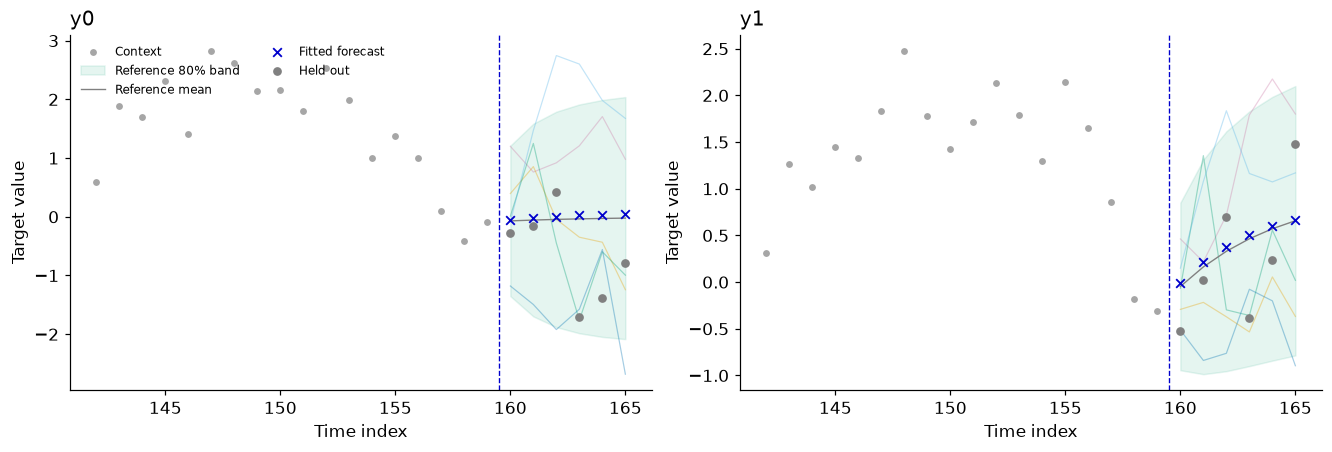

In [3]:
fig, axes = plt.subplots(1, N_TARGETS, figsize=(12, 4), constrained_layout=True)
future = case.task.future_index.to_numpy()
path_colors = ["#CC79A7", "#E69F00", "#009E73", "#56B4E9", "#0072B2"]
for target, ax in enumerate(axes):
    context = case.task.context.iloc[-18:, target]
    ax.scatter(context.index, context, color="0.65", s=12, label="Context")
    ax.fill_between(future, clean.quantiles[:, target, 0], clean.quantiles[:, target, -1],
                    color="#009E73", alpha=0.10, label="Reference 80% band")
    for sample, color in enumerate(path_colors):
        ax.plot(future, clean.samples[sample, :, target], color=color,
                alpha=0.35, linewidth=0.8)
    ax.plot(future, clean.point[:, target], color="0.5", linewidth=0.9, label="Reference mean")
    ax.scatter(future, fitted.point[:, target], color="#0000CC", marker="x", s=32,
               linewidths=1.2, label="Fitted forecast", zorder=4)
    ax.scatter(future, case.observed.iloc[:, target], color="0.5", s=22, label="Held out", zorder=3)
    ax.set(title=case.task.target_names[target], xlabel="Time index", ylabel="Target value")
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
axes[0].legend(fontsize=8, ncol=2, loc="upper left")
plt.show()

Read matching colored paths across the two panels: one sample describes both targets together. The fitted blue crosses are separate estimated point forecasts; the green reference bands do not claim uncertainty coverage for that fitted model.

## Shuffle identities, preserve marginals

`dependence_shuffle` independently permutes samples at each `(horizon, target)`. Points, supplied quantiles, and sorted samples at every coordinate stay fixed. The assertions make the consequence exact: marginal CRPS cannot change beyond floating-point tolerance. Both temporal and cross-target dependence are disrupted here.

In [4]:
np.testing.assert_array_equal(clean.point, shuffled.point)
np.testing.assert_array_equal(clean.quantiles, shuffled.quantiles)
np.testing.assert_array_equal(np.sort(clean.samples, axis=0), np.sort(shuffled.samples, axis=0))
observed = case.observed.to_numpy()
clean_crps = metrics.crps(observed, clean.samples)
shuffled_crps = metrics.crps(observed, shuffled.samples)
np.testing.assert_allclose(clean_crps, shuffled_crps, atol=1e-12, rtol=1e-12)

display(pd.DataFrame({"quantity": ["Maximum sorted-marginal difference", "Marginal CRPS difference",
                                    "Maximum raw joint-array difference"],
                      "value": [np.max(np.abs(np.sort(clean.samples, axis=0) -
                                                np.sort(shuffled.samples, axis=0))),
                                shuffled_crps - clean_crps,
                                np.max(np.abs(shuffled.samples - clean.samples))]}))


,quantity,value
0,Maximum sorted-marginal difference,0.000000
1,Marginal CRPS difference,0.000000
2,Maximum raw joint-array difference,7.040574


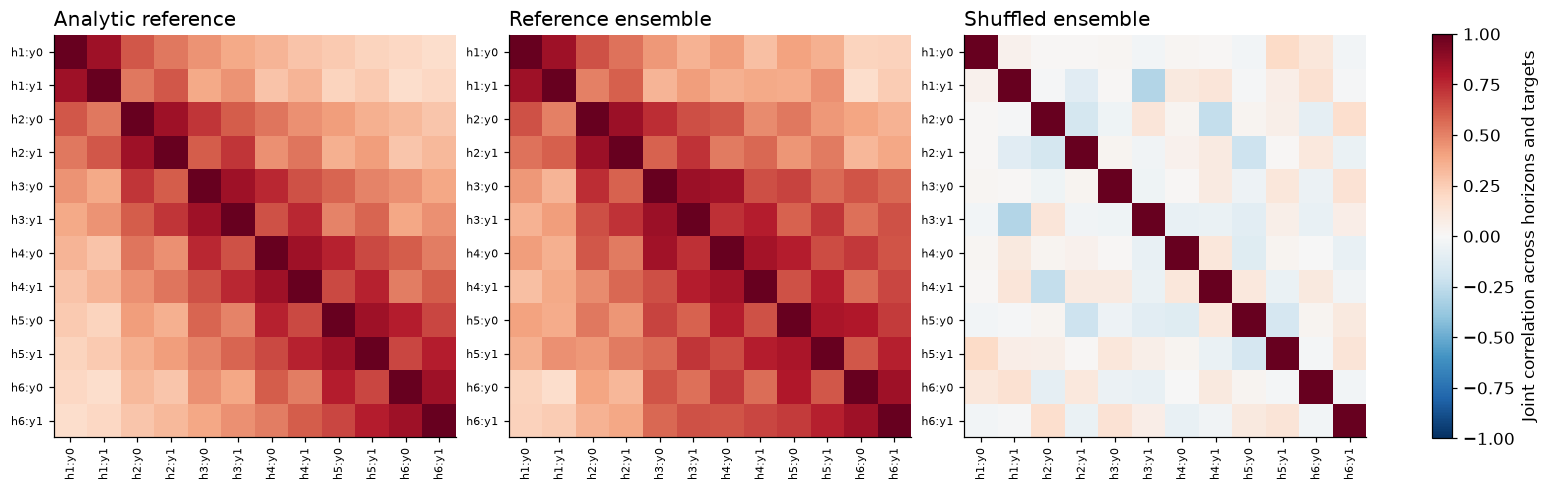

In [5]:
# Flatten in C order: (h1,y0), (h1,y1), (h2,y0), (h2,y1), ... .
coordinate_labels = [f"h{h+1}:{name}" for h in range(HORIZON) for name in case.task.target_names]

def joint_covariance(samples):
    return np.cov(samples.reshape(samples.shape[0], -1), rowvar=False, ddof=1)

def covariance_to_correlation(covariance):
    standard_deviation = np.sqrt(np.diag(covariance))
    return covariance / np.outer(standard_deviation, standard_deviation)

covariances = {"Analytic reference": case.reference.covariance,
               "Reference ensemble": joint_covariance(clean.samples),
               "Shuffled ensemble": joint_covariance(shuffled.samples)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), constrained_layout=True)
for ax, (name, covariance) in zip(axes, covariances.items()):
    plotted = ax.imshow(covariance_to_correlation(covariance), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=name, xticks=np.arange(len(coordinate_labels)),
           yticks=np.arange(len(coordinate_labels)), xticklabels=coordinate_labels,
           yticklabels=coordinate_labels)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
fig.colorbar(plotted, ax=axes, shrink=0.8, label="Joint correlation across horizons and targets")
plt.show()


The diagonal remains one in each correlation map. What changes is the off-diagonal structure connecting different horizons and targets; sampling noise also separates the clean empirical map from its analytic reference.

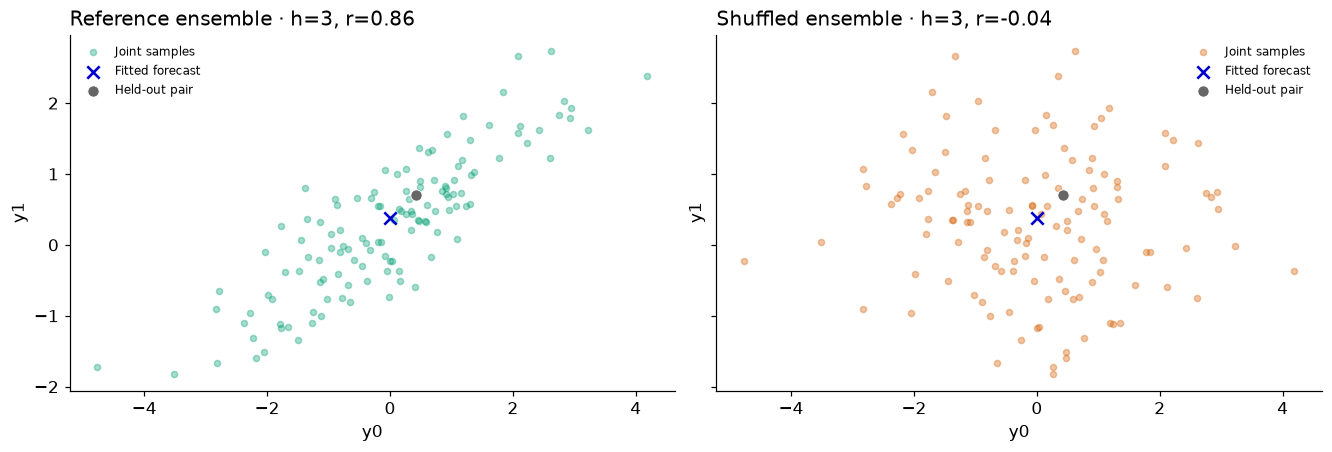

In [6]:
# A point in the cloud pairs both target values from the SAME sample at one horizon.
horizon_index = 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes, ["Reference ensemble", "Shuffled ensemble"]):
    samples = forecasts[name].samples[:, horizon_index, :]
    correlation = np.corrcoef(samples.T)[0, 1]
    ax.scatter(samples[:, 0], samples[:, 1], s=16, alpha=0.35, color=COLORS[name], label="Joint samples")
    ax.scatter(*fitted.point[horizon_index], s=65, marker="x", linewidths=1.7,
               color="#0000CC", label="Fitted forecast", zorder=5)
    ax.scatter(*observed[horizon_index], s=55, color="0.4", edgecolors="white",
               linewidths=0.6, label="Held-out pair", zorder=4)
    ax.set(title=f"{name} · h={horizon_index + 1}, r={correlation:.2f}",
           xlabel=case.task.target_names[0], ylabel=case.task.target_names[1])
    ax.legend(fontsize=8)
plt.show()

Shuffling changes how the same marginal values are paired, spreading the tilted cloud into a different joint shape. The fitted point and held-out pair are unchanged across panels; marginal summaries cannot reveal the pairing error.

## Score the joint future

Energy score uses the Euclidean norm of the complete `(H, D)` future. Variogram score compares coordinate differences, here with exponent 0.5. They can change when marginal CRPS cannot. The fitted model also has estimation error, so it is an application example rather than the mutation's clean control.

In [7]:
def forecast_scores(observed, forecast):
    return {"MAE": metrics.mae(observed, forecast.point),
            "MSE": metrics.mse(observed, forecast.point),
            "Marginal CRPS": metrics.crps(observed, forecast.samples),
            "Energy score": metrics.energy_score(observed, forecast.samples),
            "Variogram score": metrics.variogram_score(observed, forecast.samples, exponent=0.5)}

single_scores = pd.DataFrame({name: forecast_scores(observed, forecast)
                             for name, forecast in forecasts.items()}).T
np.testing.assert_allclose(single_scores.loc["Reference ensemble", ["MAE", "MSE", "Marginal CRPS"]],
                           single_scores.loc["Shuffled ensemble", ["MAE", "MSE", "Marginal CRPS"]],
                           atol=1e-12, rtol=1e-12)
display(single_scores.round(5))


,MAE,MSE,Marginal CRPS,Energy score,Variogram score
Reference ensemble,0.62832,0.61051,0.43600,1.91161,0.11931
Shuffled ensemble,0.62832,0.61051,0.43600,1.89501,0.12859
Fitted AR(1),0.65322,0.65702,0.47115,2.06959,0.11329


## Check a specific covariance null

The statistic compares empirical and analytic covariance using normalized Frobenius error. Calibration uses equal-size ensembles drawn independently from the **exact conditional reference law**. With `B=99`, the rank p-value is `(1 + number of null statistics ≥ observed) / 100`; minimum 0.01, declared per-check `alpha=0.05`.

`FAIL` detects covariance inconsistency under that null, not a unique bug; variance errors can also trigger it. `PASS` does not establish full distributional calibration. Even clean reference ensembles can reject, so there is no clean-PASS assertion.

In [8]:
B, ALPHA = 99, 0.05
single_checks = {}
for name in ["Reference ensemble", "Shuffled ensemble"]:
    single_checks[name] = covariance_dependence_check(
        case.reference, forecasts[name].samples, seed=4029, n_calibration=B, alpha=ALPHA)

single_check_table = pd.DataFrame([
    {"forecast": name, "status": check.status, "p_value": check.evidence["p_value"],
     "statistic": check.evidence["statistic"], "alpha": check.evidence["alpha"],
     "minimum_p_value": check.evidence["minimum_p_value"]}
    for name, check in single_checks.items()
])
display(single_check_table)
for name, check in single_checks.items():
    print(f"{name}: {check.message}")
# Deliberately no assertion that a random clean ensemble must PASS.


,forecast,status,p_value,statistic,alpha,minimum_p_value
0,Reference ensemble,PASS,0.64,0.132173,0.05,0.01
1,Shuffled ensemble,FAIL,0.01,0.888703,0.05,0.01


Reference ensemble: No covariance discrepancy detected at the declared level; this does not establish equality of distributions.
Shuffled ensemble: Ensemble covariance differs from the specified reference at the declared per-check level.


## Repeat on independent cases

Compare shuffled and original scores within each of 32 seeds, then summarize their differences. The two covariance checks share calibration draws within a case. Report clean false alarms alongside detections; per-check alpha does not control the chance of any rejection across the notebook.

In [9]:
N_CASES = 32
repeated_scores, repeated_checks = [], []
for seed in range(500, 500 + N_CASES):
    run = scenario.generate(seed=seed)
    reference_run = run.reference.forecast(n_samples=N_SAMPLES, seed=10_000 + seed)
    shuffled_run = mutate_forecast(reference_run, "dependence_shuffle", seed=20_000 + seed)
    np.testing.assert_array_equal(np.sort(reference_run.samples, axis=0),
                                  np.sort(shuffled_run.samples, axis=0))
    for name, prediction in [("Reference ensemble", reference_run),
                             ("Shuffled ensemble", shuffled_run)]:
        repeated_scores.append({"seed": seed, "forecast": name,
                                **forecast_scores(run.observed.to_numpy(), prediction)})
        check = covariance_dependence_check(run.reference, prediction.samples,
                                            seed=30_000 + seed, n_calibration=B, alpha=ALPHA)
        repeated_checks.append({"seed": seed, "forecast": name, "status": check.status,
                                "rejected": check.status == "FAIL",
                                "p_value": check.evidence["p_value"]})
per_seed_scores = pd.DataFrame(repeated_scores)
per_seed_checks = pd.DataFrame(repeated_checks)
assert len(per_seed_scores) == 2 * N_CASES
print(f"Finished {N_CASES} paired independent cases with {B} calibration ensembles per check.")


Finished 32 paired independent cases with 99 calibration ensembles per check.


In [10]:
def wilson_interval(successes, total, z=1.96):
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    radius = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return center - radius, center + radius

rejection_rows = []
for name, group in per_seed_checks.groupby("forecast", sort=False):
    count = int(group["rejected"].sum())
    lower, upper = wilson_interval(count, len(group))
    rejection_rows.append({"forecast": name, "rejected": count,
                           "independent_cases": len(group), "rejection_rate": count / len(group),
                           "lower_95_Wilson": lower, "upper_95_Wilson": upper})
rejection_summary = pd.DataFrame(rejection_rows)
display(rejection_summary.round(4))
print("For the reference ensemble, rejection is a false alarm under the specified null.")
print("Wilson intervals describe each rate separately; there is no multiplicity adjustment.")


,forecast,rejected,independent_cases,rejection_rate,lower_95_Wilson,upper_95_Wilson
0,Reference ensemble,1,32,0.0312,0.0055,0.1574
1,Shuffled ensemble,32,32,1.0000,0.8928,1.0000


For the reference ensemble, rejection is a false alarm under the specified null.
Wilson intervals describe each rate separately; there is no multiplicity adjustment.


In [11]:
score_names = ["MAE", "MSE", "Marginal CRPS", "Energy score", "Variogram score"]
paired_differences = {}
comparison_rows = []
for score in score_names:
    table = per_seed_scores.pivot(index="seed", columns="forecast", values=score)
    differences = table["Shuffled ensemble"] - table["Reference ensemble"]
    paired_differences[score] = differences.to_numpy()
    standard_error = differences.std(ddof=1) / np.sqrt(len(differences))
    comparison_rows.append({"score": score,
                            "reference_mean": table["Reference ensemble"].mean(),
                            "shuffled_mean": table["Shuffled ensemble"].mean(),
                            "mean_difference": differences.mean(),
                            "seed_standard_error": standard_error,
                            "approx_lower_95": differences.mean() - 1.96 * standard_error,
                            "approx_upper_95": differences.mean() + 1.96 * standard_error})
comparison = pd.DataFrame(comparison_rows).set_index("score")
for score in ["MAE", "MSE", "Marginal CRPS"]:
    np.testing.assert_allclose(paired_differences[score], 0.0, atol=1e-12, rtol=1e-12)
display(comparison.round(6))


,reference_mean,shuffled_mean,mean_difference,seed_standard_error,approx_lower_95,approx_upper_95
score,,,,,,
MAE,0.923677,0.923677,0.000000,0.000000,0.000000,0.000000
MSE,1.358690,1.358690,0.000000,0.000000,0.000000,0.000000
Marginal CRPS,0.664191,0.664191,0.000000,0.000000,-0.000000,0.000000
Energy score,2.717371,2.793601,0.076230,0.014792,0.047238,0.105223
Variogram score,0.162186,0.193815,0.031629,0.007237,0.017444,0.045814


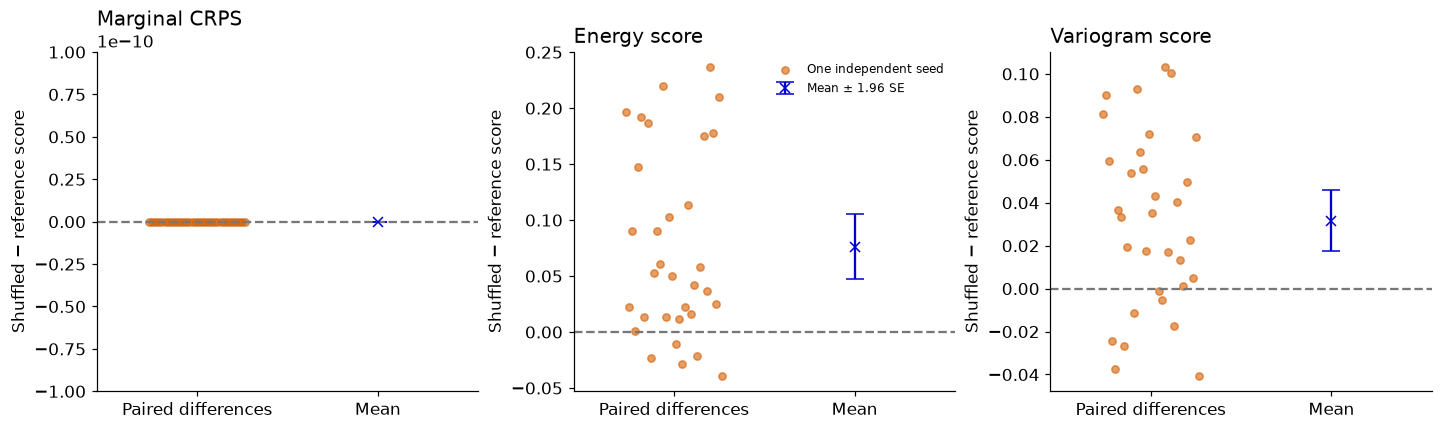

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, score in zip(axes, ["Marginal CRPS", "Energy score", "Variogram score"]):
    differences = paired_differences[score]
    row = comparison.loc[score]
    x = np.linspace(-0.12, 0.12, len(differences))  # Fixed jitter; no extra randomness.
    ax.scatter(x, differences, s=23, alpha=0.6, color="#D55E00", label="One independent seed")
    ax.errorbar(0.45, row["mean_difference"], yerr=1.96 * row["seed_standard_error"],
                fmt="x", capsize=6, color="#0000CC", markersize=6, label="Mean ± 1.96 SE")
    ax.axhline(0, color="#777777", linestyle="--")
    ax.set(title=score, ylabel="Shuffled − reference score",
           xticks=[0, 0.45], xticklabels=["Paired differences", "Mean"], xlim=(-0.25, 0.7))
    if score == "Marginal CRPS":
        ax.set_ylim(-1e-10, 1e-10)
axes[1].legend(fontsize=8)
plt.show()


The marginal difference stays at numerical zero; joint-score changes vary by seed. Intervals are mean ± 1.96 standard errors of **32 independent paired differences**, not of individual horizons, targets, or ensemble members. Panel scales differ; a positive loss difference favors the original forecast, while an interval spanning zero leaves that average effect unresolved.

## Bypass the controlled fault

Disabling the shuffle on the original forecast restores its sample identities. This paired intervention does not reconstruct dependence from an already shuffled output: marginals alone are insufficient.

In [13]:
repaired = mutate_forecast(clean, "dependence_shuffle", enabled=False)
np.testing.assert_array_equal(repaired.samples, clean.samples)
np.testing.assert_array_equal(repaired.quantiles, clean.quantiles)
assert repaired.validate(case.task) == []
repair_scores = forecast_scores(observed, repaired)
np.testing.assert_allclose(list(repair_scores.values()),
                           list(forecast_scores(observed, clean).values()))
display(pd.DataFrame({"original": forecast_scores(observed, clean),
                      "shuffled": forecast_scores(observed, shuffled),
                      "bypass_repair": repair_scores}).round(5))


,original,shuffled,bypass_repair
MAE,0.62832,0.62832,0.62832
MSE,0.61051,0.61051,0.61051
Marginal CRPS,0.43600,0.43600,0.43600
Energy score,1.91161,1.89501,1.91161
Variogram score,0.11931,0.12859,0.11931


## Change one thing

- Set innovation correlation to zero. Temporal dependence remains while `phi` is nonzero.
- Also set `phi=0`; inspect whether the mutation is still distinguishable.
- Increase samples or reduce shuffle strength in both mutation calls.
- Add a third target, adapting means, scales, and plots. Declare scaling before joint scoring.

For your model, preserve sample identities through transforms and serialization. Independent target quantiles do not supply a joint trajectory law. On real data, joint scores remain useful, but the covariance check needs a valid known reference. Overlapping rolling origins do not inherit this notebook's independent-seed uncertainty calculation.

## Scope and reading

Scores are scale-, horizon-, and dimension-dependent: compare like-for-like setups. Empirical energy score includes diagonal pairs and does not divide its norm by dimension. The variogram score equally weights distinct flattened-coordinate pairs and divides by their count; it cannot identify every distributional error. Reported intervals are approximate Monte Carlo intervals without multiplicity adjustment.

The fitted plug-in model is not an exact-reference sampler and is not judged by the covariance null here.

[Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437) · [Scheuerer and Hamill (2015)](https://doi.org/10.1175/MWR-D-14-00269.1)

Continue with [27 · Joint financial uncertainty](27_joint_financial_uncertainty.ipynb) for correlated composed processes, shared Merton jumps, CCC-GARCH and joint hidden regimes, with explicit joint-reference capabilities.